In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
from scipy import stats
import matplotlib.pyplot as plt

## Value at Risk (VaR)

VaR - what is loss expected on a bad day

Z-score - how many std away from the mean
Z-score = (value - mean) / std

VaR = mean - zscore x std dev

In [2]:
sp500 = yf.download("SPY", period="10y")["Close"]["SPY"]
daily_returns = sp500.pct_change(fill_method=None).dropna()

var = daily_returns.quantile(0.05)

print(f"VaR (95%) : {var * 100:.2f}%")

[*********************100%***********************]  1 of 1 completed

VaR (95%) : -1.67%


## Max Drawdown

Max DD - what the worst peak to bottom drop

$500 ← peak
  ↓
  ↓  (dropping...)
  ↓
$350 ← bottom
  ↓
$600 ← recovered

Max DD = drop from $500 to $350
       = $350 - $500 / $500 = -30%


In [3]:
rolling_peak = sp500.cummax()

drawdown = (sp500 - rolling_peak) / rolling_peak

max_drawdown = drawdown.min()

print(f"Max Drawdown : {max_drawdown * 100:.2f}%")

Max Drawdown : -33.72%


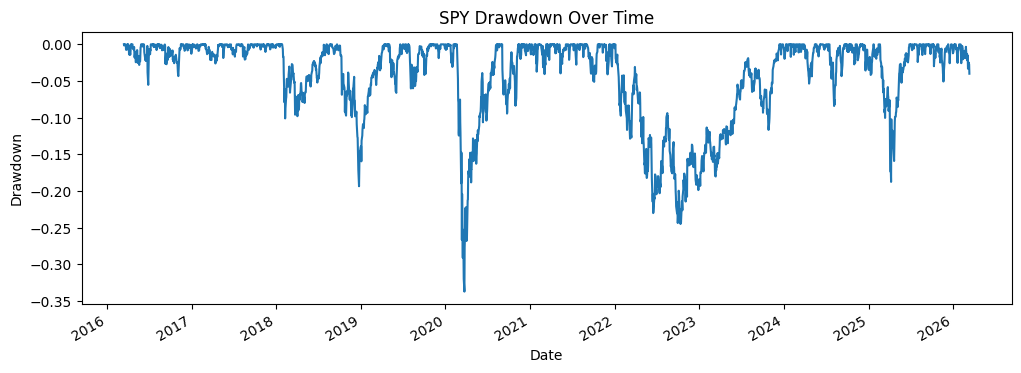

In [4]:
drawdown.plot(figsize=(12,4), title="SPY Drawdown Over Time")
import matplotlib.pyplot as plt
plt.ylabel("Drawdown")
plt.show()